In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB


from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [51]:
flower_dataset = pd.read_csv("../ML-Lec-3/Iris.csv")

In [52]:
flower_dataset

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


In [53]:
flower_dataset.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [54]:
flower_dataset.duplicated().sum()

np.int64(0)

In [55]:
flower_dataset.isnull().sum()

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

In [56]:
flower_dataset["Species"].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

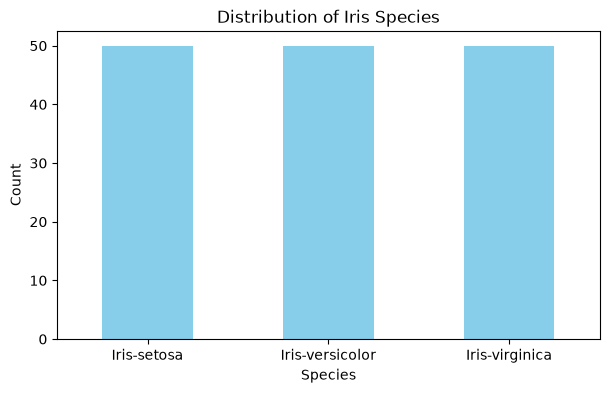

In [57]:
flower_dataset["Species"].value_counts().plot(
    kind="bar",
    figsize=(7, 4),
    color="skyblue"
)

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

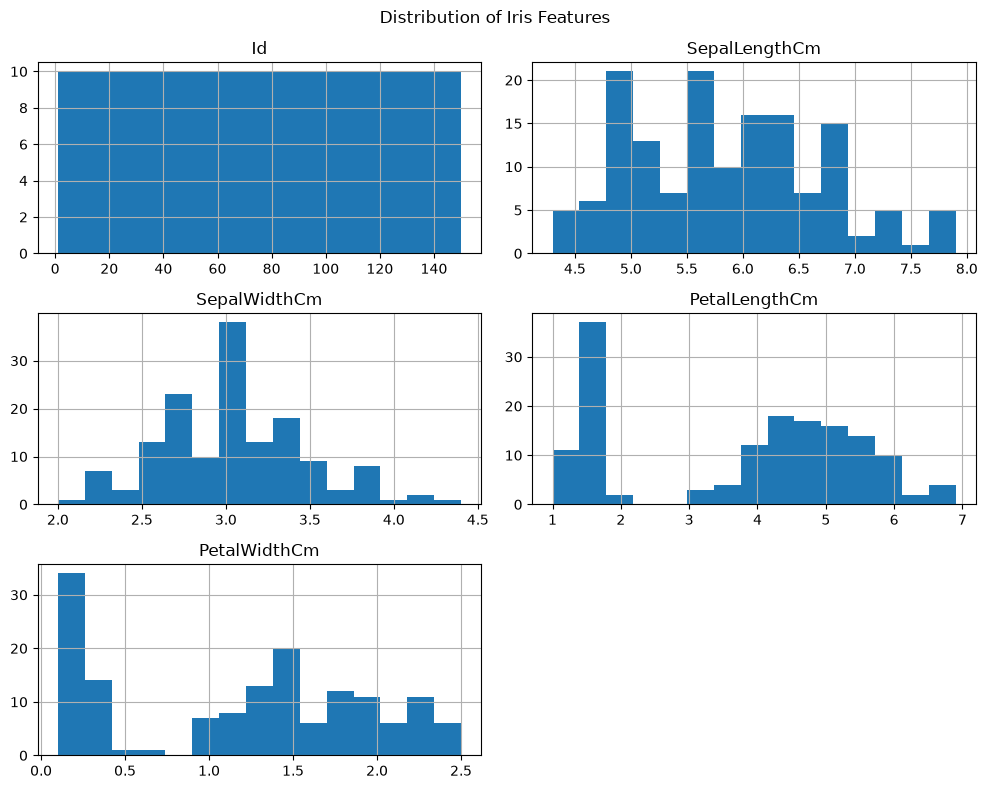

In [58]:
flower_dataset.hist(figsize=(10, 8), bins=15)

plt.suptitle("Distribution of Iris Features")
plt.tight_layout()
plt.show()

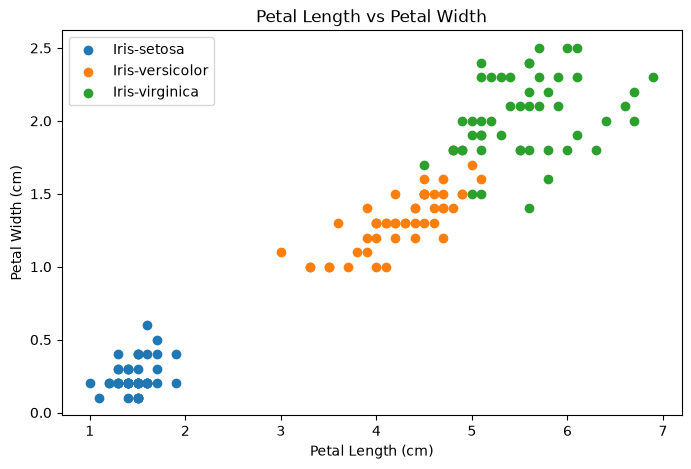

In [59]:
plt.figure(figsize=(8, 5))

for species in flower_dataset["Species"].unique():
    subset = flower_dataset[flower_dataset["Species"] == species]

    plt.scatter(
        subset["PetalLengthCm"],
        subset["PetalWidthCm"],
        label=species
    )

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Petal Length vs Petal Width")
plt.legend()
plt.show()

In [60]:
X = flower_dataset.drop(columns=["Species", "Id"])
y = flower_dataset["Species"]

In [61]:
X

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [62]:
y

0         Iris-setosa
1         Iris-setosa
2         Iris-setosa
3         Iris-setosa
4         Iris-setosa
            ...      
145    Iris-virginica
146    Iris-virginica
147    Iris-virginica
148    Iris-virginica
149    Iris-virginica
Name: Species, Length: 150, dtype: str

In [63]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  150 non-null    float64
 1   SepalWidthCm   150 non-null    float64
 2   PetalLengthCm  150 non-null    float64
 3   PetalWidthCm   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


In [64]:
y.info()

<class 'pandas.Series'>
RangeIndex: 150 entries, 0 to 149
Series name: Species
Non-Null Count  Dtype
--------------  -----
150 non-null    str  
dtypes: str(1)
memory usage: 3.3 KB


In [65]:
le = LabelEncoder() #It acts as a transalator assigning label to a nummerical value

y = le.fit_transform(y) #Sort the unique values from y and then assigneing them numerical values starting from 0

print("Encoded Species:", le.classes_)
print("Encoded Values:", np.unique(y))

Encoded Species: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']
Encoded Values: [0 1 2]


In [66]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.50,
    random_state=42,
    stratify=y #It ensures that all three flower species are represented proportionally in both sets.
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (75, 4)
Testing data: (75, 4)


In [67]:
#The assignment says to test on 100% of the data.
#Therefore, we'll retain the original complete dataset separately for evaluation:

X_full = X.copy()
y_full = y.copy()

print("Complete dataset:", X_full.shape)
print("Complete target:", y_full.shape)

Complete dataset: (150, 4)
Complete target: (150,)


In [68]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_full_scaled = scaler.transform(X_full)

print("Scaled training data:", X_train_scaled.shape)
print("Scaled complete data:", X_full_scaled.shape)

#Note: Scaling is particularly important for KNN and Logistic Regression.
       # Gaussian Naive Bayes does not generally require feature scaling, but using the scaled features consistently is acceptable here.

Scaled training data: (75, 4)
Scaled complete data: (150, 4)


In [70]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [71]:
knn_pred = knn.predict(X_full_scaled)

print("KNN Predictions:")
print(knn_pred)

KNN Predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 1 2 2 2 2
 2 2 2 2 2 2 2 2 1 2 2 2 1 2 2 2 2 2 2 2 2 2 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]


In [75]:
log_reg = LogisticRegression(max_iter=200) #max_iter=200 allows the algorithm more iterations to converge during training.

In [76]:
log_reg.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",200
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'l

In [77]:
log_reg_pred = log_reg.predict(X_full_scaled)

print("Logistic Regression Predictions:")
print(log_reg_pred)

Logistic Regression Predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 1 1
 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 1 2 2 2 2
 2 2 2 2 2 2 2 2 1 2 2 2 2 2 2 2 2 2 2 2 2 2 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]


In [78]:
nb = GaussianNB()

In [79]:
nb.fit(X_train_scaled, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](3,)","[25.,25.,25.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](3,)","[0.33,0.33,0.33]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](3,)","[0,1,2]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](3, 4)","[[-1.05, 0.7 ,-1.29,-1.24], [ 0.11,-0.7 , 0.25, 0.13], [ 0.94,-0.01, 1.05, 1.12]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](3, 4)","[[0.13,0.9 ,0.01,0.02], [0.29,0.44,0.07,0.06], [0.58,0.68,0.1 ,0.11]]"


In [80]:
nb_pred = nb.predict(X_full_scaled)

print("Naive Bayes Predictions:")
print(nb_pred)

Naive Bayes Predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 1 1
 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 1 2 2 2 2
 2 2 2 2 2 2 2 2 1 2 2 2 2 2 2 2 2 2 2 2 2 2 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]


In [81]:
comparison = pd.DataFrame({
    "Actual": le.inverse_transform(y_full),
    "KNN": le.inverse_transform(knn_pred),
    "Logistic Regression": le.inverse_transform(log_reg_pred),
    "Naive Bayes": le.inverse_transform(nb_pred)
})

comparison

,Actual,KNN,Logistic Regression,Naive Bayes
0,Iris-setosa,Iris-setosa,Iris-setosa,Iris-setosa
1,Iris-setosa,Iris-setosa,Iris-setosa,Iris-setosa
2,Iris-setosa,Iris-setosa,Iris-setosa,Iris-setosa
3,Iris-setosa,Iris-setosa,Iris-setosa,Iris-setosa
4,Iris-setosa,Iris-setosa,Iris-setosa,Iris-setosa
...,...,...,...,...
145,Iris-virginica,Iris-virginica,Iris-virginica,Iris-virginica
146,Iris-virginica,Iris-virginica,Iris-virginica,Iris-virginica
147,Iris-virginica,Iris-virginica,Iris-virginica,Iris-virginica
148,Iris-virginica,Iris-virginica,Iris-virginica,Iris-virginica


In [84]:
knn_accuracy = accuracy_score(y_full, knn_pred)

log_reg_accuracy = accuracy_score(y_full, log_reg_pred)

nb_accuracy = accuracy_score(y_full, nb_pred)

print("KNN Accuracy:", knn_accuracy)
print("Logistic Regression Accuracy:", log_reg_accuracy)
print("Naive Bayes Accuracy:", nb_accuracy)

KNN Accuracy: 0.96
Logistic Regression Accuracy: 0.96
Naive Bayes Accuracy: 0.96


In [87]:
print("KNN Accuracy:", round(knn_accuracy * 100, 2), "%")
print("Logistic Regression Accuracy:", round(log_reg_accuracy * 100, 2), "%")
print("Naive Bayes Accuracy:", round(nb_accuracy * 100, 2), "%")

KNN Accuracy: 96.0 %
Logistic Regression Accuracy: 96.0 %
Naive Bayes Accuracy: 96.0 %


In [88]:
knn_cm = confusion_matrix(y_full, knn_pred)

print("KNN Confusion Matrix:")
print(knn_cm)

KNN Confusion Matrix:
[[50  0  0]
 [ 0 49  1]
 [ 0  5 45]]


In [89]:
log_reg_cm = confusion_matrix(y_full, log_reg_pred)

print("Logistic Regression Confusion Matrix:")
print(log_reg_cm)

Logistic Regression Confusion Matrix:
[[50  0  0]
 [ 0 48  2]
 [ 0  4 46]]


In [90]:
nb_cm = confusion_matrix(y_full, nb_pred)

print("Naive Bayes Confusion Matrix:")
print(nb_cm)

Naive Bayes Confusion Matrix:
[[50  0  0]
 [ 0 48  2]
 [ 0  4 46]]


In [91]:
print("KNN Classification Report")
print(classification_report(
    y_full,
    knn_pred,
    target_names=le.classes_
))

KNN Classification Report
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        50
Iris-versicolor       0.91      0.98      0.94        50
 Iris-virginica       0.98      0.90      0.94        50

       accuracy                           0.96       150
      macro avg       0.96      0.96      0.96       150
   weighted avg       0.96      0.96      0.96       150



In [92]:
print("Logistic Regression Classification Report")
print(classification_report(
    y_full,
    log_reg_pred,
    target_names=le.classes_
))

Logistic Regression Classification Report
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        50
Iris-versicolor       0.92      0.96      0.94        50
 Iris-virginica       0.96      0.92      0.94        50

       accuracy                           0.96       150
      macro avg       0.96      0.96      0.96       150
   weighted avg       0.96      0.96      0.96       150



In [93]:
print("Naive Bayes Classification Report")
print(classification_report(
    y_full,
    nb_pred,
    target_names=le.classes_
))

Naive Bayes Classification Report
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        50
Iris-versicolor       0.92      0.96      0.94        50
 Iris-virginica       0.96      0.92      0.94        50

       accuracy                           0.96       150
      macro avg       0.96      0.96      0.96       150
   weighted avg       0.96      0.96      0.96       150



In [94]:
results = pd.DataFrame({
    "Model": [
        "KNN",
        "Logistic Regression",
        "Naive Bayes"
    ],
    "Accuracy": [
        knn_accuracy,
        log_reg_accuracy,
        nb_accuracy
    ]
})

results["Accuracy (%)"] = (
    results["Accuracy"] * 100
).round(2)

results = results.sort_values(
    by="Accuracy",
    ascending=False
)

print(results)

                 Model  Accuracy  Accuracy (%)
0                  KNN      0.96          96.0
1  Logistic Regression      0.96          96.0
2          Naive Bayes      0.96          96.0


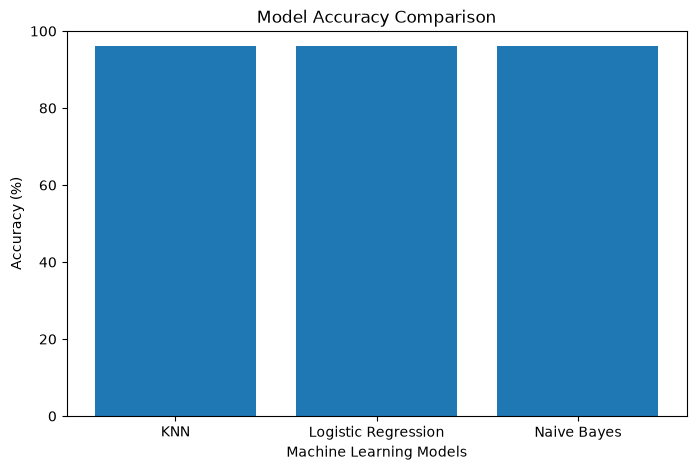

In [95]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["Model"],
    results["Accuracy (%)"]
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")

plt.ylim(0, 100)
plt.show()

In [96]:
best_model = results.iloc[0]

print("Best Model:", best_model["Model"])
print("Best Accuracy:", best_model["Accuracy (%)"], "%")

Best Model: KNN
Best Accuracy: 96.0 %
